In [1]:
pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [2]:
from ultralytics import YOLO
from PIL import Image

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
!unzip "/content/Helemet_YML.zip"

Archive:  /content/Helemet_YML.zip
  inflating: data/data.yaml          
  inflating: data/test/images/a.jpeg  
  inflating: data/test/images/aa.jpeg  
  inflating: data/test/images/aaa.jpeg  
  inflating: data/test/images/aab.jpeg  
  inflating: data/test/images/aac.jpeg  
  inflating: data/test/images/aad.jpeg  
  inflating: data/test/images/aae.jpeg  
  inflating: data/test/images/aaf.jpeg  
  inflating: data/test/images/aag.jpeg  
  inflating: data/test/images/aah.jpeg  
  inflating: data/test/images/aai.jpeg  
  inflating: data/test/images/aaj.jpeg  
  inflating: data/test/images/ab.jpeg  
  inflating: data/test/images/ac.jpeg  
  inflating: data/test/images/ad.jpeg  
  inflating: data/test/images/ae.jpeg  
  inflating: data/test/images/af.jpeg  
  inflating: data/test/images/ag.jpeg  
  inflating: data/test/images/ah.jpeg  
  inflating: data/test/images/ai.jpeg  
  inflating: data/test/images/aj.jpeg  
  inflating: data/test/images/ak.jpeg  
  inflating: data/test/images/al.jpeg 

In [4]:
model= YOLO("yolo26n.pt")

### Before Model train make sure you must changed the test and train data Address in `.yml` file

- If we provide only the image folder in data.yaml, how does YOLO know where the labels are?

- The answer is: YOLO automatically finds the corresponding label files using the folder structure and filenames.

In [6]:
model_trained=model.train(data="/content/data/data.yaml", epochs=10, imgsz=640)

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

In [7]:
results=model.predict('/content/data/test/images/ab.jpeg')


image 1/1 /content/data/test/images/ab.jpeg: 640x640 2 driver_with_helmets, 1 bike, 1 driver, 1 passenger, 10.4ms
Speed: 3.3ms preprocess, 10.4ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


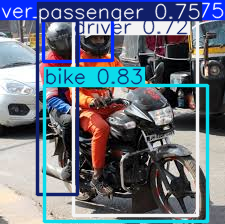

In [8]:
results[0].show()

In [9]:
results[0]

ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
depth: None
keypoints: None
masks: None
names: {0: 'driver_with_helmet', 1: 'bike', 2: 'driver', 3: 'passenger_with_helemt', 4: 'passenger', 5: 'driver_without_helmet', 6: 'passenger_without_helemt'}
obb: None
orig_img: array([[[144, 135, 131],
        [141, 132, 128],
        [136, 127, 123],
        ...,
        [211, 205, 206],
        [209, 206, 208],
        [133, 135, 145]],

       [[130, 121, 117],
        [127, 118, 114],
        [125, 116, 112],
        ...,
        [ 81,  76,  77],
        [ 74,  71,  73],
        [ 73,  74,  78]],

       [[124, 118, 113],
        [118, 112, 107],
        [114, 108, 103],
        ...,
        [190, 187, 189],
        [203, 198, 199],
        [129, 122, 119]],

       ...,

       [[108, 113, 116],
        [120, 125, 128],
        [131, 136, 139],
        ...,
        [115, 107, 107],
        [115, 107, 107],
        [105, 100,  97]],



# Best Model
1. model = YOLO("yolo26n.pt") loads the original pretrained model.



2. model.train() trains it on your dataset.



3. Ultralytics saves best.pt and last.pt.



4. After successful training, the current Ultralytics implementation loads the best checkpoint back into the original model object.



5. Therefore, model.predict() uses the trained best model.

In [11]:
Best_model=YOLO("/content/runs/detect/train-2/weights/best.pt")


image 1/1 /content/data/test/images/ab.jpeg: 640x640 2 driver_with_helmets, 1 bike, 1 driver, 1 passenger, 10.3ms
Speed: 2.1ms preprocess, 10.3ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


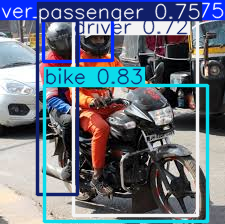

In [12]:
res=Best_model.predict('/content/data/test/images/ab.jpeg')
res[0].show()

### therefore same result with best model too..


image 1/1 /content/data/test/images/zzzzzzzzzzzzzzzzzz (9).jpeg: 384x640 1 bike, 1 driver, 1 driver_without_helmet, 52.2ms
Speed: 2.1ms preprocess, 52.2ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)


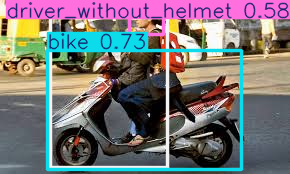

In [13]:
results=model.predict('/content/data/test/images/zzzzzzzzzzzzzzzzzz (9).jpeg')
results[0].show()


image 1/1 /content/data/test/images/zzzzzzzzzzzzzzzzzz (8).jpeg: 384x640 1 driver_with_helmet, 1 bike, 1 driver, 2 passengers, 13.5ms
Speed: 2.4ms preprocess, 13.5ms inference, 1.8ms postprocess per image at shape (1, 3, 384, 640)


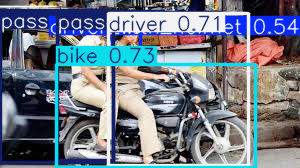

In [14]:
results=model.predict('/content/data/test/images/zzzzzzzzzzzzzzzzzz (8).jpeg')
results[0].show()

In [15]:
results[0]

ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
depth: None
keypoints: None
masks: None
names: {0: 'driver_with_helmet', 1: 'bike', 2: 'driver', 3: 'passenger_with_helemt', 4: 'passenger', 5: 'driver_without_helmet', 6: 'passenger_without_helemt'}
obb: None
orig_img: array([[[ 44,  39,  40],
        [ 46,  40,  41],
        [ 51,  43,  44],
        ...,
        [ 28,  26,  38],
        [ 29,  27,  39],
        [ 36,  35,  45]],

       [[ 55,  55,  55],
        [ 58,  56,  56],
        [ 60,  55,  56],
        ...,
        [ 19,  17,  29],
        [ 24,  22,  34],
        [ 35,  34,  44]],

       [[ 46,  55,  52],
        [ 46,  55,  52],
        [ 49,  56,  53],
        ...,
        [ 14,  12,  24],
        [ 27,  23,  35],
        [ 43,  39,  50]],

       ...,

       [[100, 100, 100],
        [106, 106, 106],
        [116, 116, 116],
        ...,
        [185, 190, 191],
        [186, 191, 192],
        [187, 192, 193]],



### Exporting the model

In [17]:
model.export(format='onnx')

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/content/runs/detect/train-2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 11, 8400) (5.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 303ms
Prepared 4 packages in 507ms
Installed 4 packages in 32ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming 

'/content/runs/detect/train-2/weights/best.onnx'